# Blackjack con Q-learning y SARSA

Este notebook construye una versión tabular y autocontenida del problema clásico de blackjack. El objetivo no es solo entrenar un agente: se muestran el espacio de estados, las acciones, las recompensas, los retornos, la Q-table, las actualizaciones TD, las políticas aprendidas y una comparación experimental entre **Q-learning** y **SARSA**.

La formulación sigue el blackjack episódico de Sutton y Barto: baraja infinita, el crupier se planta desde 17, acciones *pedir* o *plantarse*, y recompensa terminal en $\{-1,0,+1\}$.

## 1. Supuestos del entorno

- Las cartas se extraen con reemplazo. Por tanto, no se hace conteo de cartas.
- El as vale 11 si no produce una suma mayor que 21; en caso contrario vale 1.
- Si la suma del jugador es menor que 12 se pide automáticamente: plantarse nunca puede ser óptimo allí.
- El crupier pide mientras su suma es menor que 17.
- No se incluyen doblar, separar, rendirse ni seguro.
- Un episodio es una mano completa. Los naturales terminan antes de que el agente tome una decisión.

Estas simplificaciones producen un MDP finito de 200 estados de decisión y 2 acciones.

## 2. Formulación como proceso de decisión de Markov

El estado se representa por

$$S_t=(p_t,d_t,u_t),$$

donde $p_t\in\{12,\ldots,21\}$ es la suma del jugador, $d_t\in\{1,\ldots,10\}$ es la carta visible del crupier y $u_t\in\{0,1\}$ indica si existe un as utilizable. Las acciones son $A_t\in\{\text{plantarse},\text{pedir}\}$.

Con una baraja infinita, la distribución de la siguiente carta no depende de las cartas vistas anteriormente. Por ello, el triple $(p_t,d_t,u_t)$ contiene la información necesaria para predecir el futuro y satisface la propiedad de Markov.

In [1]:
from collections import defaultdict
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SEED = 2026
STICK, HIT = 0, 1
ACTION_NAMES = {STICK: "Plantarse", HIT: "Pedir"}
CARD_LABELS = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10"]

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_rows", 20)
print("Librerías cargadas. Acciones:", ACTION_NAMES)

Librerías cargadas. Acciones: {0: 'Plantarse', 1: 'Pedir'}


In [2]:
CARDS = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 10)

def draw_card(rng):
    """Baraja infinita: 10, J, Q y K producen cuatro copias del valor 10."""
    return rng.choice(CARDS)

def hand_value(hand):
    """Retorna (suma, as_utilizable). Cada as inicialmente cuenta como 1."""
    total = sum(hand)
    usable_ace = 1 in hand and total + 10 <= 21
    return total + 10 if usable_ace else total, usable_ace

def is_natural(hand):
    return len(hand) == 2 and hand_value(hand)[0] == 21

class BlackjackEnv:
    """Entorno mínimo con una interfaz reset/step."""
    def __init__(self, seed=SEED):
        self.rng = random.Random(seed)

    def _state(self):
        player_sum, usable = hand_value(self.player)
        return (player_sum, self.dealer[0], usable)

    def reset(self):
        self.player = [draw_card(self.rng), draw_card(self.rng)]
        self.dealer = [draw_card(self.rng), draw_card(self.rng)]

        while hand_value(self.player)[0] < 12:
            self.player.append(draw_card(self.rng))

        if is_natural(self.player):
            reward = 0 if is_natural(self.dealer) else 1
            return None, reward, True
        if is_natural(self.dealer):
            return None, -1, True
        return self._state(), 0, False

    def step(self, action):
        if action == HIT:
            self.player.append(draw_card(self.rng))
            if hand_value(self.player)[0] > 21:
                return None, -1, True
            return self._state(), 0, False

        while hand_value(self.dealer)[0] < 17:
            self.dealer.append(draw_card(self.rng))
        player_sum, _ = hand_value(self.player)
        dealer_sum, _ = hand_value(self.dealer)
        reward = 1 if dealer_sum > 21 or player_sum > dealer_sum else -1 if player_sum < dealer_sum else 0
        return None, reward, True

env_demo = BlackjackEnv()
print("Ejemplo de reset:", env_demo.reset())

Ejemplo de reset: ((18, 9, False), 0, False)


In [3]:
states = pd.DataFrame(
    [(p, d, u) for p in range(12, 22) for d in range(1, 11) for u in (False, True)],
    columns=["suma_jugador", "carta_crupier", "as_utilizable"]
)
print("Número de estados:", len(states))
print("Número de pares estado-acción:", len(states) * 2)
print(states.head(12).to_string(index=False))

Número de estados: 200
Número de pares estado-acción: 400
 suma_jugador  carta_crupier  as_utilizable
           12              1          False
           12              1           True
           12              2          False
           12              2           True
           12              3          False
           12              3           True
           12              4          False
           12              4           True
           12              5          False
           12              5           True
           12              6          False
           12              6           True


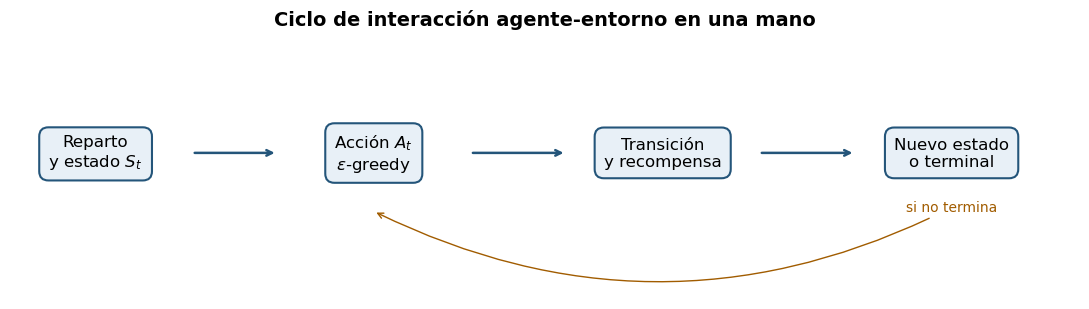

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axis("off")
nodes = [(0.08, "Reparto\ny estado $S_t$"), (0.34, "Acción $A_t$\n" + r"$\epsilon$-greedy"),
         (0.61, "Transición\ny recompensa"), (0.88, "Nuevo estado\no terminal")]
for x, label in nodes:
    ax.text(x, 0.55, label, ha="center", va="center", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.55", fc="#E8F0F7", ec="#24557A", lw=1.5))
for (x1, _), (x2, _) in zip(nodes[:-1], nodes[1:]):
    ax.annotate("", xy=(x2-0.09, 0.55), xytext=(x1+0.09, 0.55),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#24557A"))
ax.annotate("si no termina", xy=(0.34, 0.33), xytext=(0.88, 0.33), ha="center",
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.25", color="#A15C00"),
            color="#A15C00", fontsize=10)
ax.set_title("Ciclo de interacción agente-entorno en una mano", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

## 3. Recompensa y retorno

Las recompensas intermedias son cero y la recompensa terminal es

$$R_T=\begin{cases}+1,&\text{victoria},\\0,&\text{empate},\\-1,&\text{derrota}.\end{cases}$$

El retorno desde el instante $t$ es

$$G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots.$$

Se usa $\gamma=1$ porque la mano termina en pocos pasos y no se desea descontar el resultado final. Como todas las recompensas anteriores al final valen cero, en este problema $G_t$ coincide con el resultado terminal desde cualquier decisión de la misma mano.

In [5]:
example_episode = pd.DataFrame({
    "t": [0, 1],
    "estado": ["(13, 6, sin as)", "(18, 6, sin as)"],
    "acción": ["Pedir", "Plantarse"],
    "recompensa_observada": [0, 1],
    "retorno_Gt_gamma_1": [1, 1],
})
print("Trayectoria ilustrativa: el jugador termina ganando.")
print(example_episode.to_string(index=False))

Trayectoria ilustrativa: el jugador termina ganando.
 t          estado    acción  recompensa_observada  retorno_Gt_gamma_1
 0 (13, 6, sin as)     Pedir                     0                   1
 1 (18, 6, sin as) Plantarse                     1                   1


## 4. Valores de estado y de acción

Para una política $\pi$, el valor de un estado es el retorno esperado

$$v_\pi(s)=\mathbb{E}_\pi[G_t\mid S_t=s],$$

y el valor de una acción en ese estado es

$$q_\pi(s,a)=\mathbb{E}_\pi[G_t\mid S_t=s,A_t=a].$$

La Q-table aproxima $q(s,a)$. En esta implementación es un arreglo de forma $(10,10,2,2)$: suma del jugador, carta del crupier, indicador de as y acción. Equivale a una tabla de 200 filas por 2 acciones. La política greedy se obtiene mediante $\pi(s)=\arg\max_a Q(s,a)$.

## 5. Exploración frente a explotación

Durante el entrenamiento se utiliza una política $\epsilon$-greedy:

$$A_t=\begin{cases}\text{acción aleatoria},&\text{con probabilidad }\epsilon,\\
\arg\max_a Q(S_t,a),&\text{con probabilidad }1-\epsilon.\end{cases}$$

La exploración evita que el agente descarte prematuramente acciones que todavía no conoce. Aquí $\epsilon$ decrece desde 1 hasta 0.05. Los empates entre acciones se resuelven aleatoriamente para no introducir un sesgo artificial hacia *plantarse* o *pedir*.

## 6. Q-learning: control TD *off-policy*

La ecuación de optimalidad de Bellman sugiere el objetivo

$$R_{t+1}+\gamma\max_{a'}Q(S_{t+1},a').$$

Q-learning desplaza el valor actual hacia ese objetivo:

$$Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\alpha\left[R_{t+1}+\gamma\max_{a'}Q(S_{t+1},a')-Q(S_t,A_t)\right].$$

Es *off-policy* porque la conducta puede ser exploratoria, pero la actualización supone que en el estado siguiente se escogerá la mejor acción estimada. Por eso apunta directamente a $q_*$ y resulta especialmente apropiado cuando el entrenamiento ocurre en simulación y la política final será greedy.

## 7. SARSA: control TD *on-policy*

SARSA usa la quíntupla $(S_t,A_t,R_{t+1},S_{t+1},A_{t+1})$:

$$Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\alpha\left[R_{t+1}+\gamma Q(S_{t+1},A_{t+1})-Q(S_t,A_t)\right].$$

Es *on-policy*: aprende el valor de la misma política $\epsilon$-greedy con la que actúa. Mientras $\epsilon>0$, el objetivo incluye la posibilidad de explorar en el siguiente paso. En problemas donde explorar puede conducir a estados peligrosos, SARSA suele aprender políticas más cautelosas. En blackjack simulado esa diferencia es menor porque una exploración desafortunada no produce un riesgo persistente fuera del episodio.

In [6]:
def q_index(state):
    player_sum, dealer_card, usable = state
    return player_sum - 12, dealer_card - 1, int(usable)

def epsilon_greedy(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.choice((STICK, HIT))
    values = Q[q_index(state)]
    best = np.flatnonzero(values == values.max())
    return int(rng.choice(best.tolist()))

def epsilon_schedule(episode, n_episodes, start=1.0, end=0.05):
    fraction = episode / max(1, n_episodes - 1)
    return start * (end / start) ** fraction

def train(algorithm, episodes=300_000, alpha=0.05, gamma=1.0, seed=SEED):
    """algorithm debe ser 'q_learning' o 'sarsa'."""
    if algorithm not in {"q_learning", "sarsa"}:
        raise ValueError("Algoritmo no reconocido")

    env = BlackjackEnv(seed)
    action_rng = random.Random(seed + 10_000)
    Q = np.zeros((10, 10, 2, 2), dtype=float)
    returns = np.zeros(episodes, dtype=float)
    lengths = np.zeros(episodes, dtype=int)

    for episode in range(episodes):
        epsilon = epsilon_schedule(episode, episodes)
        state, initial_reward, done = env.reset()
        if done:                       # natural: no hubo decisión que actualizar
            returns[episode] = initial_reward
            continue

        action = epsilon_greedy(Q, state, epsilon, action_rng)
        total_reward = 0

        while not done:
            next_state, reward, done = env.step(action)
            total_reward += reward
            lengths[episode] += 1

            if done:
                target = reward
                next_action = None
            elif algorithm == "q_learning":
                target = reward + gamma * np.max(Q[q_index(next_state)])
                next_action = epsilon_greedy(Q, next_state, epsilon, action_rng)
            else:                     # SARSA: el objetivo usa la próxima acción real
                next_action = epsilon_greedy(Q, next_state, epsilon, action_rng)
                target = reward + gamma * Q[q_index(next_state) + (next_action,)]

            idx = q_index(state) + (action,)
            td_error = target - Q[idx]
            Q[idx] += alpha * td_error

            state, action = next_state, next_action

        returns[episode] = total_reward

    return Q, returns, lengths

print("Funciones de selección y entrenamiento definidas.")

Funciones de selección y entrenamiento definidas.


## 8. Entrenamiento comparable

Se entrenan ambos algoritmos con la misma cantidad de episodios y los mismos hiperparámetros:

- episodios: 300 000 por algoritmo;
- tasa de aprendizaje: $\alpha=0.05$;
- descuento: $\gamma=1$;
- exploración: $\epsilon:1\rightarrow0.05$;
- inicialización: $Q(s,a)=0$.

Una tasa constante es conveniente para una demostración compacta, aunque la convergencia asintótica formal requiere tasas decrecientes que satisfagan $\sum_t\alpha_t=\infty$ y $\sum_t\alpha_t^2<\infty$, además de visitas persistentes a todos los pares estado-acción.

In [7]:
EPISODES = 300_000
ALPHA = 0.05
GAMMA = 1.0

Q_ql, returns_ql, lengths_ql = train("q_learning", EPISODES, ALPHA, GAMMA, seed=SEED)
Q_sa, returns_sa, lengths_sa = train("sarsa", EPISODES, ALPHA, GAMMA, seed=SEED + 1)

print("Entrenamiento terminado.")
print("Forma de cada Q-table:", Q_ql.shape)
print("Retorno medio en los últimos 20 000 episodios:")
print(f"  Q-learning: {returns_ql[-20_000:].mean(): .4f}")
print(f"  SARSA:      {returns_sa[-20_000:].mean(): .4f}")

Entrenamiento terminado.
Forma de cada Q-table: (10, 10, 2, 2)
Retorno medio en los últimos 20 000 episodios:
  Q-learning: -0.0737
  SARSA:      -0.0805


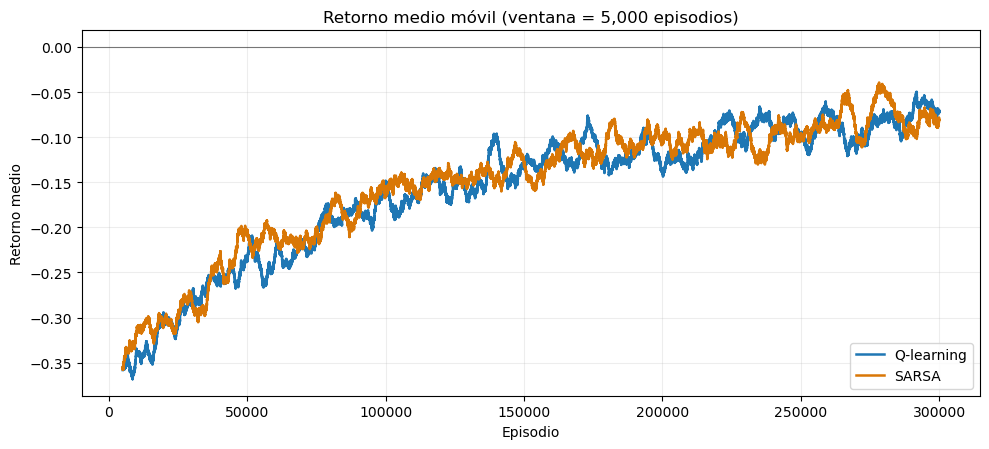

In [8]:
def moving_average(values, window=5000):
    kernel = np.ones(window) / window
    return np.convolve(values, kernel, mode="valid")

window = 5000
ma_ql = moving_average(returns_ql, window)
ma_sa = moving_average(returns_sa, window)
x = np.arange(window - 1, EPISODES)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(x, ma_ql, label="Q-learning", lw=1.8, color="#1F77B4")
ax.plot(x, ma_sa, label="SARSA", lw=1.8, color="#D97706")
ax.axhline(0, color="black", lw=0.8, alpha=0.5)
ax.set(title=f"Retorno medio móvil (ventana = {window:,} episodios)",
       xlabel="Episodio", ylabel="Retorno medio")
ax.grid(alpha=0.22)
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
def q_table_dataframe(Q):
    rows = []
    for p in range(12, 22):
        for d in range(1, 11):
            for usable in (False, True):
                q_stick, q_hit = Q[p-12, d-1, int(usable)]
                rows.append((p, d, usable, q_stick, q_hit,
                             ACTION_NAMES[int(q_hit > q_stick)], max(q_stick, q_hit)))
    return pd.DataFrame(rows, columns=[
        "suma_jugador", "carta_crupier", "as_utilizable",
        "Q_plantarse", "Q_pedir", "acción_greedy", "V_max"
    ])

qtable_ql = q_table_dataframe(Q_ql)
qtable_sa = q_table_dataframe(Q_sa)

sample_states = [(12, 4, False), (16, 10, False), (18, 6, True), (20, 10, False)]
sample = qtable_ql.set_index(["suma_jugador", "carta_crupier", "as_utilizable"]).loc[sample_states]
print("Muestra de la Q-table de Q-learning:")
print(sample.round(3).to_string())

Muestra de la Q-table de Q-learning:
                                          Q_plantarse  Q_pedir acción_greedy  V_max
suma_jugador carta_crupier as_utilizable                                           
12           4             False               -0.499   -0.148         Pedir -0.148
16           10            False               -0.742   -0.733         Pedir -0.733
18           6             True                 0.160    0.182         Pedir  0.182
20           10            False                0.560   -0.989     Plantarse  0.560


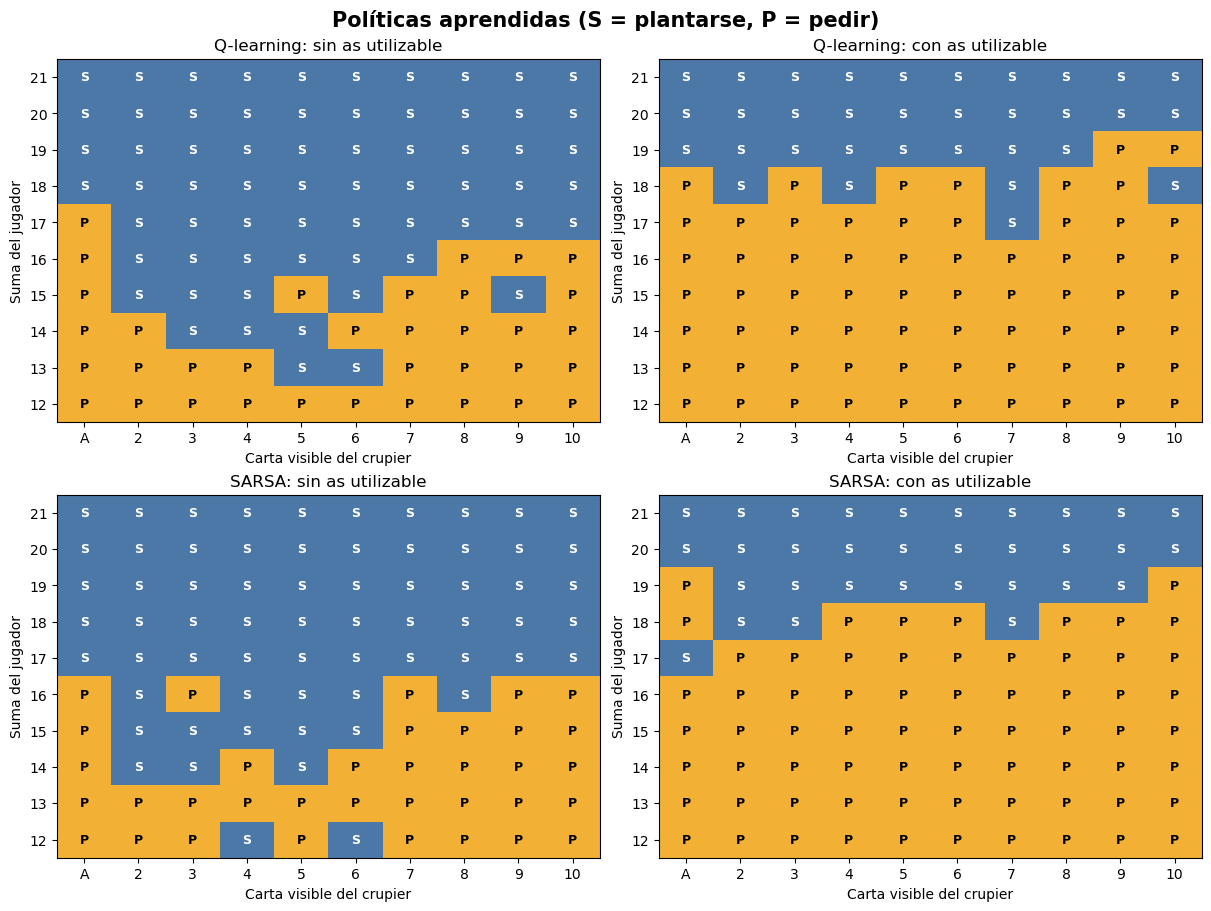

In [10]:
def policy_matrix(Q, usable_ace):
    return np.argmax(Q[:, :, int(usable_ace), :], axis=-1)

def plot_policy(ax, Q, usable_ace, title):
    matrix = policy_matrix(Q, usable_ace)
    ax.imshow(matrix, origin="lower", cmap=ListedColormap(["#4C78A8", "#F2B134"]),
              vmin=0, vmax=1, aspect="auto")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, "S" if matrix[i, j] == STICK else "P",
                    ha="center", va="center", color="white" if matrix[i, j] == STICK else "black",
                    fontsize=9, weight="bold")
    ax.set_xticks(range(10), CARD_LABELS)
    ax.set_yticks(range(10), range(12, 22))
    ax.set_xlabel("Carta visible del crupier")
    ax.set_ylabel("Suma del jugador")
    ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
plot_policy(axes[0, 0], Q_ql, False, "Q-learning: sin as utilizable")
plot_policy(axes[0, 1], Q_ql, True, "Q-learning: con as utilizable")
plot_policy(axes[1, 0], Q_sa, False, "SARSA: sin as utilizable")
plot_policy(axes[1, 1], Q_sa, True, "SARSA: con as utilizable")
fig.suptitle("Políticas aprendidas (S = plantarse, P = pedir)", fontsize=15, weight="bold")
plt.show()

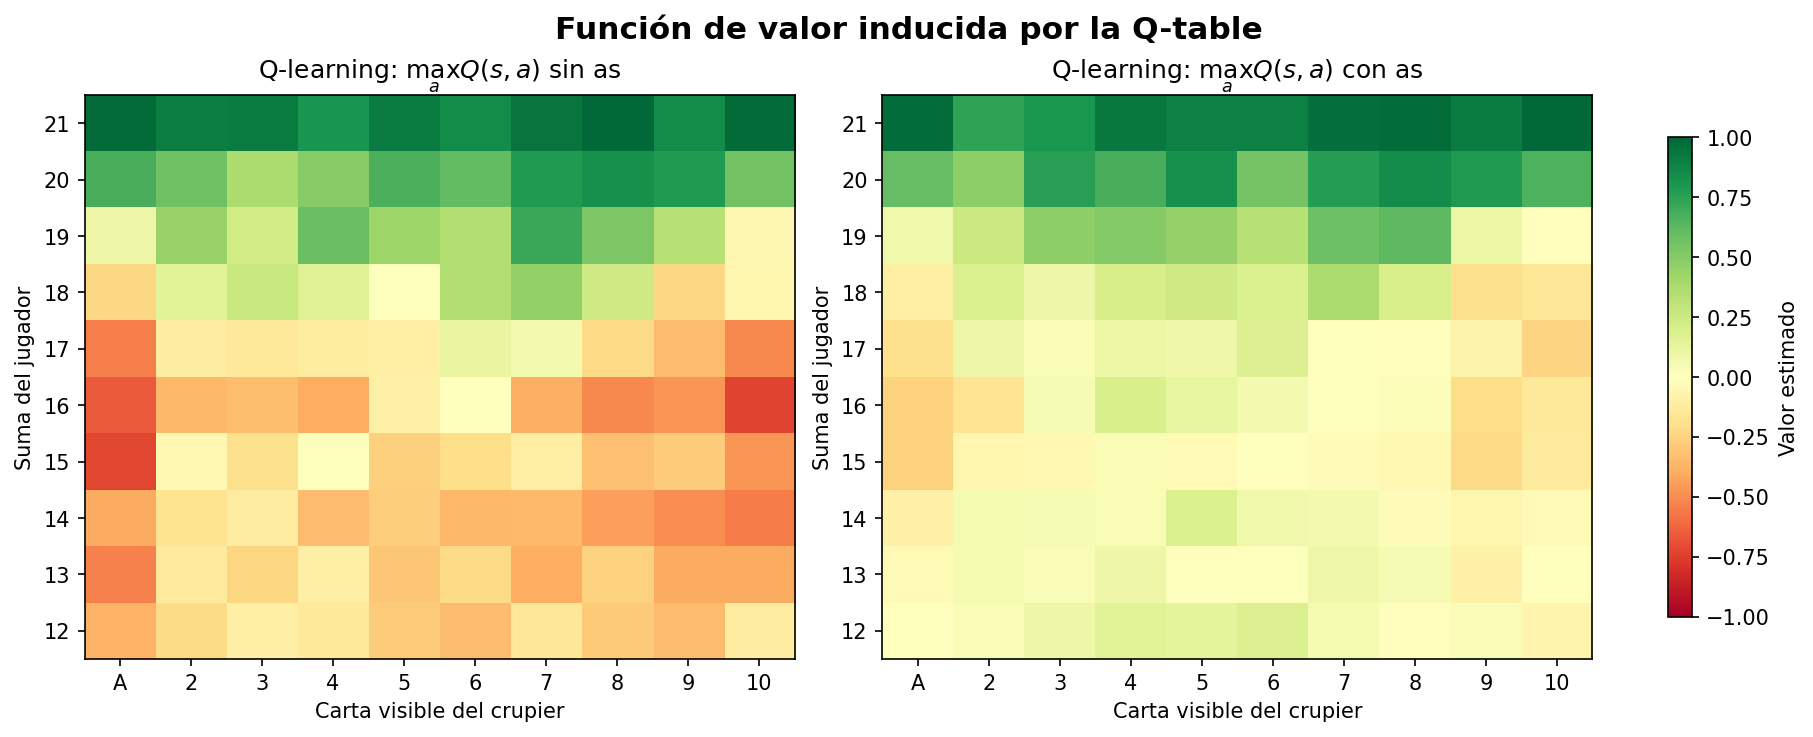

In [11]:
def plot_values(ax, Q, usable_ace, title):
    values = np.max(Q[:, :, int(usable_ace), :], axis=-1)
    im = ax.imshow(values, origin="lower", cmap="RdYlGn", aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(10), CARD_LABELS)
    ax.set_yticks(range(10), range(12, 22))
    ax.set_xlabel("Carta visible del crupier")
    ax.set_ylabel("Suma del jugador")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
im = plot_values(axes[0], Q_ql, False, r"Q-learning: $\max_a Q(s,a)$ sin as")
plot_values(axes[1], Q_ql, True, r"Q-learning: $\max_a Q(s,a)$ con as")
fig.colorbar(im, ax=axes, shrink=0.85, label="Valor estimado")
fig.suptitle("Función de valor inducida por la Q-table", fontsize=15, weight="bold")
plt.show()

In [11]:
def evaluate(Q, games=100_000, seed=999):
    env = BlackjackEnv(seed)
    rng = random.Random(seed + 1)
    rewards = []
    for _ in range(games):
        state, reward, done = env.reset()
        while not done:
            action = epsilon_greedy(Q, state, epsilon=0.0, rng=rng)
            state, reward, done = env.step(action)
        rewards.append(reward)
    rewards = np.asarray(rewards)
    return {
        "victorias_%": 100 * np.mean(rewards == 1),
        "empates_%": 100 * np.mean(rewards == 0),
        "derrotas_%": 100 * np.mean(rewards == -1),
        "retorno_medio": rewards.mean(),
    }

comparison = pd.DataFrame({
    "Q-learning": evaluate(Q_ql, seed=1001),
    "SARSA": evaluate(Q_sa, seed=2001),
}).T
print("Evaluación de las políticas greedy en 100 000 manos nuevas:")
print(comparison.round(4).to_string())

Evaluación de las políticas greedy en 100 000 manos nuevas:
            victorias_%  empates_%  derrotas_%  retorno_medio
Q-learning       42.804      8.811      48.385        -0.0558
SARSA            42.516      8.935      48.549        -0.0603


In [12]:
def trace_episode(Q, seed=31415):
    env = BlackjackEnv(seed)
    rng = random.Random(seed + 1)
    state, reward, done = env.reset()
    rows = []
    t = 0
    if done:
        rows.append({"t": 0, "estado": "natural", "acción": "-", "R_t+1": reward})
    while not done:
        action = epsilon_greedy(Q, state, epsilon=0.0, rng=rng)
        old_state = state
        state, reward, done = env.step(action)
        rows.append({"t": t, "estado": str(old_state), "acción": ACTION_NAMES[action], "R_t+1": reward})
        t += 1
    G = 0
    for row in reversed(rows):
        G = row["R_t+1"] + GAMMA * G
        row["G_t"] = G
    return pd.DataFrame(rows)

for candidate_seed in range(31415, 31615):
    trace = trace_episode(Q_ql, seed=candidate_seed)
    if len(trace) >= 2:
        break
print("Traza de una mano con la política greedy de Q-learning:")
print(trace.to_string(index=False))

Traza de una mano con la política greedy de Q-learning:
 t         estado    acción  R_t+1  G_t
 0 (13, 9, False)     Pedir      0 -1.0
 1 (18, 9, False) Plantarse     -1 -1.0


## 9. Interpretación

1. **La Q-table no es una tabla de recompensas.** Cada entrada estima el retorno futuro esperado después de escoger una acción en un estado.
2. **El retorno medio puede ser negativo aun con una política razonable.** El jugador actúa antes que el crupier y pierde inmediatamente al exceder 21.
3. **Q-learning y SARSA pueden producir políticas muy parecidas.** Al reducir $\epsilon$, la acción que SARSA usa en su objetivo se vuelve casi greedy y la diferencia entre los algoritmos disminuye.
4. **Q-learning es la elección principal para esta simulación.** Aprende hacia la política greedy óptima aun mientras la conducta explora.
5. **SARSA sigue siendo una comparación útil.** Hace visible la diferencia entre aprender el valor de la conducta actual y aprender el valor de una política objetivo distinta.

Las pequeñas irregularidades de una política tabular concreta se deben al muestreo finito, a la tasa de aprendizaje constante y a que algunos estados —especialmente con as utilizable— aparecen con menor frecuencia.

## 10. Límites y extensiones

- Una baraja finita requeriría incluir información sobre la composición restante para conservar la propiedad de Markov.
- Si se incorporan doblar o separar, el espacio de acciones y el estado deben ampliarse.
- Una recompensa monetaria debería modelar apuestas y el pago especial del blackjack natural.
- Para estudiar convergencia con mayor rigor pueden usarse más episodios, $\epsilon_t\to0$ y una tasa $\alpha_t$ decreciente por cada par $(s,a)$.
- Expected SARSA o Double Q-learning permiten estudiar, respectivamente, menor varianza del objetivo y reducción del sesgo de maximización.

### Referencias

- Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed., ejemplos y secciones 5.1, 6.4 y 6.5.
- Watkins, C. J. C. H. (1989). *Learning from Delayed Rewards*. Tesis doctoral, King's College.
- Dayan, P. y Niv, Y. (2008). “Reinforcement learning: The Good, The Bad and The Ugly”. *Current Opinion in Neurobiology*, 18.

In [ ]:
def recomendar_accion(suma_jugador, carta_crupier, as_utilizable, modelo="q_learning"):
    """Devuelve la acción recomendada y los Q-valores para un estado dado."""
    tablas = {"q_learning": Q_ql, "sarsa": Q_sa}
    if modelo not in tablas:
        raise ValueError("modelo debe ser 'q_learning' o 'sarsa'")
    if not (1 <= carta_crupier <= 10):
        raise ValueError("carta_crupier debe estar entre 1 y 10")

    if suma_jugador < 12:
        return {
            "estado": (suma_jugador, carta_crupier, as_utilizable),
            "modelo": modelo,
            "accion": "Pedir",
            "motivo": "Suma < 12: se pide automáticamente (regla del entorno, sin Q-valores aprendidos)",
            "Q_plantarse": None,
            "Q_pedir": None,
        }
    if suma_jugador > 21:
        raise ValueError("suma_jugador no puede ser mayor que 21")

    Q = tablas[modelo]
    q_stick, q_hit = Q[q_index((suma_jugador, carta_crupier, as_utilizable))]
    accion = ACTION_NAMES[int(q_hit > q_stick)]

    return {
        "estado": (suma_jugador, carta_crupier, as_utilizable),
        "modelo": modelo,
        "accion": accion,
        "Q_plantarse": round(float(q_stick), 4),
        "Q_pedir": round(float(q_hit), 4),
    }


def consulta_interactiva():
    """Pide un estado por teclado y muestra la recomendación de ambos modelos."""
    print("Recomendación de acción en tiempo real (escribe 'salir' para terminar)\n")
    while True:
        entrada = input("Suma del jugador (12-21, o <12 para ver la regla automática): ").strip()
        if entrada.lower() == "salir":
            break
        entrada_dealer = input("Carta visible del crupier (1=As, 2-10): ").strip()
        if entrada_dealer.lower() == "salir":
            break
        entrada_as = input("¿As utilizable? (s/n): ").strip()
        if entrada_as.lower() == "salir":
            break

        try:
            suma = int(entrada)
            carta = int(entrada_dealer)
            as_util = entrada_as.lower() in ("s", "si", "sí", "y", "yes")

            for modelo in ("q_learning", "sarsa"):
                r = recomendar_accion(suma, carta, as_util, modelo)
                if r["Q_plantarse"] is None:
                    print(f"[{modelo:10s}] Estado {r['estado']} -> {r['accion']}  ({r['motivo']})")
                else:
                    print(f"[{modelo:10s}] Estado {r['estado']} -> {r['accion']}  "
                          f"(Q_plantarse={r['Q_plantarse']}, Q_pedir={r['Q_pedir']})")
        except ValueError as e:
            print(f"Entrada inválida: {e}")
        print()


# Se ejecuta directamente al correr la celda y te pide los inputs por consola:
consulta_interactiva()

Recomendación de acción en tiempo real (escribe 'salir' para terminar)



Suma del jugador (12-21, o <12 para ver la regla automática):  15
Carta visible del crupier (1=As, 2-10):  0,10
¿As utilizable? (s/n):  s


Entrada inválida: invalid literal for int() with base 10: '0,10'



Suma del jugador (12-21, o <12 para ver la regla automática):  15
Carta visible del crupier (1=As, 2-10):  10
¿As utilizable? (s/n):  n


[q_learning] Estado (15, 10, False) -> Pedir  (Q_plantarse=-0.823, Q_pedir=-0.4693)
[sarsa     ] Estado (15, 10, False) -> Pedir  (Q_plantarse=-0.8228, Q_pedir=-0.6731)



...

[q_learning] Estado (14, 10, True) -> Pedir  (Q_plantarse=-0.5266, Q_pedir=-0.0347)
[sarsa     ] Estado (14, 10, True) -> Pedir  (Q_plantarse=-0.4651, Q_pedir=-0.2426)



Suma del jugador (12-21, o <12 para ver la regla automática):  17
Carta visible del crupier (1=As, 2-10):  10
¿As utilizable? (s/n):  s


[q_learning] Estado (17, 10, True) -> Pedir  (Q_plantarse=-0.4071, Q_pedir=-0.2448)
[sarsa     ] Estado (17, 10, True) -> Pedir  (Q_plantarse=-0.6719, Q_pedir=-0.264)



Suma del jugador (12-21, o <12 para ver la regla automática):  20
Carta visible del crupier (1=As, 2-10):  10
¿As utilizable? (s/n):  s


[q_learning] Estado (20, 10, True) -> Plantarse  (Q_plantarse=0.6621, Q_pedir=-0.1644)
[sarsa     ] Estado (20, 10, True) -> Plantarse  (Q_plantarse=0.5787, Q_pedir=-0.1929)

